In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import sys
sys.path.append('/media/dll-1/SSD 4TB/code/LEEDNet/')  # Replace with real path
from EEGDataLoader import EEGDataset
from models.LEEDNetModel import LEEDNetModel
import config
from train_eval import eval, train

model_saving_name = "/media/dll-1/SSD 4TB/EEG Datasets/experiment/nouman_conv_2/model/weights/conv_tt_02_tukl_5_aug.pt"

epochs = 30
batch_size = 64
hidden_size = 20
output_size = 3  # Binary classification
number_of_eeg_channels = 1
eval_batch = 1
threshold = 0.495
active_branches = [0,2]

/home/anaconda/anaconda3/envs/braindecode/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
train_dataset = EEGDataset(config.train_data_csv, number_of_eeg_channels=number_of_eeg_channels)
val_dataset = EEGDataset(config.val_data_csv, number_of_eeg_channels=number_of_eeg_channels)
test_dataset = EEGDataset(config.test_data_csv, number_of_eeg_channels=number_of_eeg_channels)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)#, collate_fn=collate)
val_loader = DataLoader(val_dataset, batch_size=eval_batch, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=eval_batch, shuffle=False)

In [ ]:
input = train_dataset.__getitem__(0)
input_x1 = input[1].shape
input_x2 = input[2].shape
input_x3 = input[3].shape
criterion = nn.CrossEntropyLoss()

loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

print(input_x1,input_x2,input_x3)
input_channels_list = [input_x1[1], input_x2[1], input_x3[1]]

model = LEEDNetModel(input_channels_list=input_channels_list, output_size=3)

main_output, aux_outputs = model([input[1], input[2], input[3]], active_branch_indices=active_branches)
print("Output shape:", main_output.shape) 

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001,betas=(0.9, 0.98), eps=1e-9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

torch.Size([1, 1, 400]) torch.Size([1, 33, 14]) torch.Size([1, 30, 400])
Output shape: torch.Size([1, 3])


/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


ConvParallelEEG1DModel(
  (branches): ModuleList(
    (0): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(in_features=32, out_features=3, bias=True)
    )
    (1): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(33, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(

In [14]:
model_state_dict = torch.load(model_saving_name)
# Load the state_dict into the model
model.load_state_dict(model_state_dict)


/tmp/ipykernel_126857/2470549735.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_state_dict = torch.load(model_saving_name)


<All keys matched successfully>


Running t-SNE for: Raw EEG Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: Wavelet Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: Final Fused Features...
(74774, 96)
(74774,)
t-SNE calculation complete.


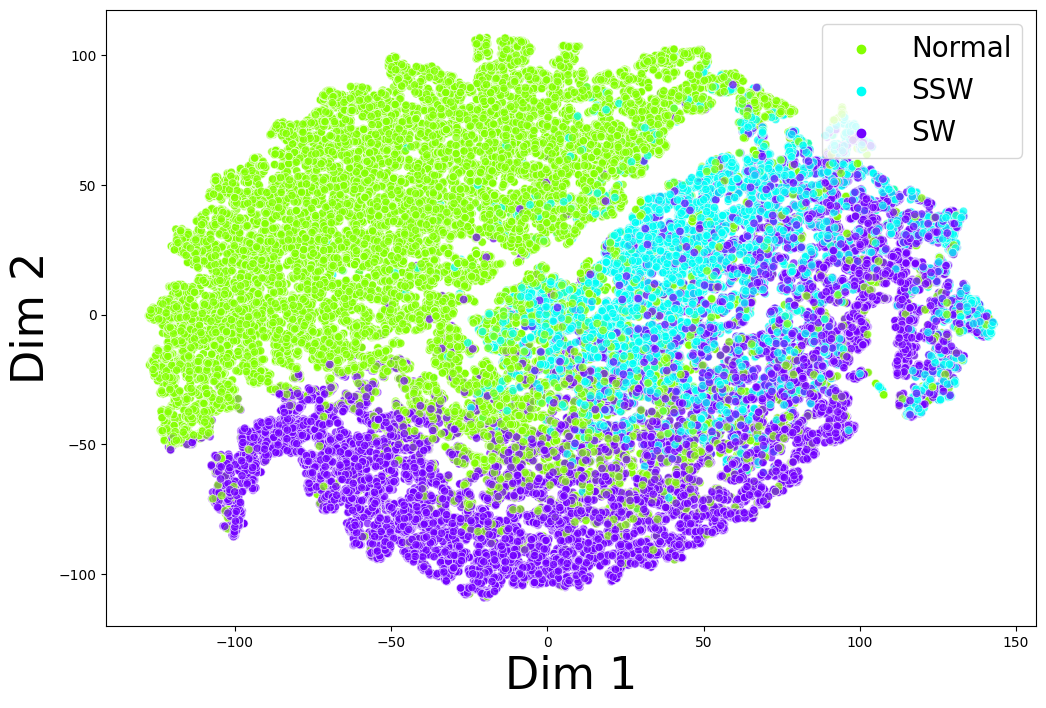

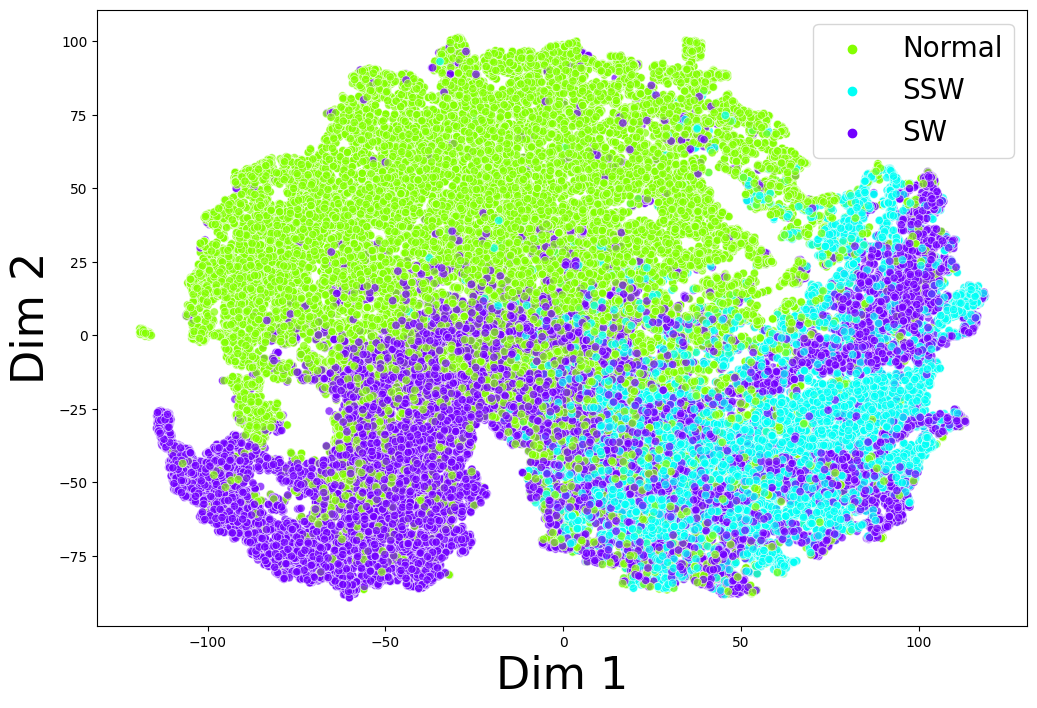

In [17]:
for ax, key, title in zip(axs, feature_keys, plot_titles):
    print(f"\nRunning t-SNE for: {title}...")
    
    features_np = np.concatenate(features[key], axis=0)
    true_labels_np = np.array(true_labels)

    print(features_np.shape)
    print(true_labels_np.shape)
    
    tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, learning_rate='auto', init='pca')
    tsne_results = tsne.fit_transform(features_np)
    print("t-SNE calculation complete.")

    label_map = {
    0: 'Normal',
    1: 'SSW',  # Sharp and Spike Wave
    2: 'SW'    # Slow Wave
    }
        

    true_labels_mapped = [label_map[label] for label in true_labels_np]

    tsne_df = pd.DataFrame({
        't-SNE Dimension 1': tsne_results[:,0],
        't-SNE Dimension 2': tsne_results[:,1],
        'Labels': true_labels_mapped 
    })

    plt.figure(figsize=(12, 8))
        
    sns.scatterplot(
        x="t-SNE Dimension 1", y="t-SNE Dimension 2",
        hue="Labels", 
        hue_order=['Normal', 'SSW', 'SW'], 
        palette=sns.color_palette("hsv", n_colors=len(label_map)), 
        data=tsne_df,
        legend="full",
        alpha=0.7
    )
    plt.xlabel('Dim 1', fontsize=32)
    plt.ylabel('Dim 2', fontsize=32)

    plt.legend(fontsize=20, title=None, loc='upper right')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()